# Causal Steering Analysis

Analyses the causal effect of injecting trajectory hypothesis directions into
the model's hidden states at many layers, and with many alpha coefficients.

Three main metrics, computed as (steered − baseline):
1. **Δ in-cat log prob** — does steering increase probability of held-out in-category tokens?
2. **Δ out-cat log prob** — does steering change probability of held-out out-of-category tokens?
3. **Δ discrimination** — change in (in-cat − out-cat) log prob gap

Conditions compared:
- `match` — steer along +trajectory (concept direction)
- `anti` — steer along −trajectory (opposite direction)
- `control_cat` — steer along trajectory of the least-similar control category
- `random` — steer along a random unit vector (unit-normed noise baseline)

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [41]:
# ── Configuration ────────────────────────────────────────────────────────────
MODEL_NAME  = "google_gemma-2-2b"
RESULTS_DIR = f"../results_final/categories/{MODEL_NAME}/steering"
MODEL_LABEL = "Gemma-2-2B"
SAVE_DIR = os.path.join("Figures_Final", MODEL_LABEL)

os.makedirs(SAVE_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(RESULTS_DIR, "steering.csv"))

with open(os.path.join(RESULTS_DIR, "hyperparams.json")) as f:
    hparams = json.load(f)

ALPHAS = sorted(df[df["condition"] != "baseline"]["alpha"].unique().tolist())
DEFAULT_ALPHA = 50  # use largest alpha for single-alpha plots

CONDITION_LABELS = {
    "match":       "Positive",
    "anti":        "Negative",
    "control_cat": "Control",
    "random":      "Random",
}

CONDITIONS = list(CONDITION_LABELS.values())
CONDITION_COLORS = {
    "Positive": "#2196F3",  # blue
    "Negative": "#F44336",  # red
    "Control":  "#FF9800",  # orange
    "Random":   "#9E9E9E",  # gray
}

print(f"Loaded {len(df)} rows")
print(f"Conditions: {df['condition'].unique().tolist()}")
print(f"Layers: {sorted(df['layer'].unique().tolist())}")
print(f"Categories: {df['category'].nunique()}")
print(f"Alphas: {ALPHAS}  |  Default: {DEFAULT_ALPHA}")

Loaded 72885 rows
Conditions: ['baseline', 'match', 'anti', 'control_cat', 'random']
Layers: [-1, 3, 6, 9, 12, 15, 18, 21, 24]
Categories: 113
Alphas: [5.0, 10.0, 20.0, 50.0]  |  Default: 50


In [42]:
# ── Compute deltas (steered − baseline) ──────────────────────────────────────
# Baseline rows have layer == -1; one per (category, support_id)
baseline = df[df["condition"] == "baseline"].copy()
baseline = baseline.rename(columns={
    "mean_log_prob_in_cat":  "baseline_in",
    "mean_log_prob_out_cat": "baseline_out",
})
baseline = baseline[["category", "support_id", "baseline_in", "baseline_out"]]

steered = df[df["condition"] != "baseline"].copy()
steered["condition"] = steered["condition"].map(CONDITION_LABELS)
steered = steered.merge(baseline, on=["category", "support_id"])

steered["delta_in"]             = steered["mean_log_prob_in_cat"]  - steered["baseline_in"]
steered["delta_out"]            = steered["mean_log_prob_out_cat"] - steered["baseline_out"]
steered["baseline_disc"]        = steered["baseline_in"]  - steered["baseline_out"]
steered["steered_disc"]         = steered["mean_log_prob_in_cat"] - steered["mean_log_prob_out_cat"]
steered["delta_discrimination"] = steered["steered_disc"] - steered["baseline_disc"]

# Default-alpha slice used by single-alpha plots
steered_default = steered[steered["alpha"] == DEFAULT_ALPHA].copy()

print(steered_default[["condition", "layer", "delta_in", "delta_out", "delta_discrimination"]]
      .groupby(["condition", "layer"]).mean().head(20))

                 delta_in  delta_out  delta_discrimination
condition layer                                           
Control   3     -0.075129   0.196607             -0.271736
          6     -0.075382   0.231517             -0.306899
          9     -0.063000   0.271731             -0.334731
          12    -0.044289   0.169556             -0.213844
          15    -0.070137   0.097981             -0.168119
          18    -0.101853   0.090390             -0.192244
          21    -0.054875  -0.017776             -0.037099
          24    -0.034351   0.010383             -0.044735
Negative  3     -0.091369   0.100959             -0.192328
          6     -0.072740   0.258591             -0.331331
          9     -0.237875   0.696788             -0.934663
          12    -0.175494   0.636492             -0.811985
          15    -0.226962   0.655785             -0.882747
          18    -0.539422   0.836493             -1.375914
          21    -0.567721   0.644428             -1.2121

## 1. Δ In-Category Log Prob by Layer and Condition

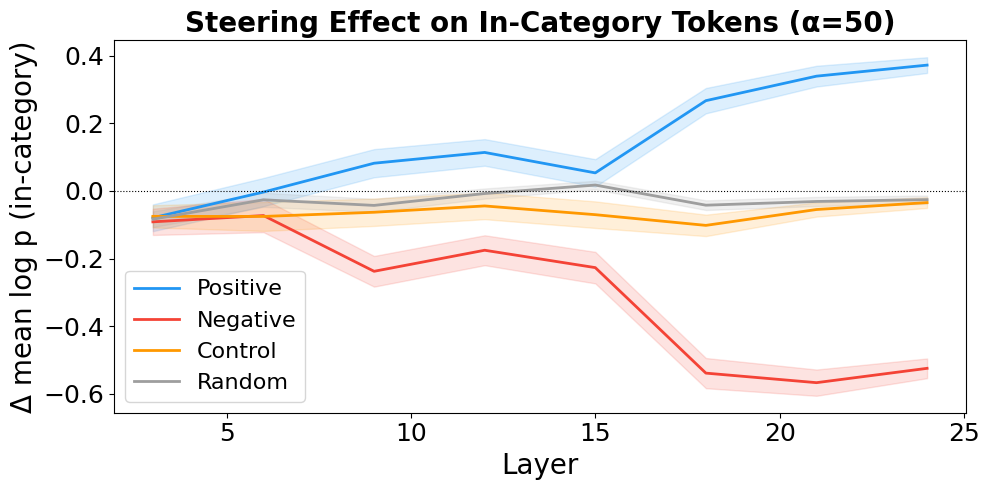

In [47]:
def plot_delta_by_layer(steered_df, metric, ylabel, title_suffix, model_label,
                        conditions=None, colors=None, ax=None):
    """Line plot of mean delta ± SEM across categories, per layer, per condition."""
    if conditions is None:
        conditions = CONDITIONS
    if colors is None:
        colors = CONDITION_COLORS

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(10, 5))

    for cond in conditions:
        sub = steered_df[steered_df["condition"] == cond]
        agg = sub.groupby(["category", "layer"])[metric].mean().reset_index()
        stats = agg.groupby("layer")[metric].agg(["mean", "sem"]).reset_index()
        ax.plot(stats["layer"], stats["mean"],
                color=colors[cond], linewidth=2, label=cond)
        ax.fill_between(stats["layer"],
                        stats["mean"] - stats["sem"],
                        stats["mean"] + stats["sem"],
                        color=colors[cond], alpha=0.15)

    ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
    ax.set_xlabel("Layer", fontsize=20)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_title(f"{title_suffix}", fontweight="bold", fontsize=20)
    ax.tick_params(axis="both", labelsize=18)
    ax.legend(fontsize=16)

    if own_fig:
        plt.tight_layout()
        plt.show()
    return fig


fig = plot_delta_by_layer(
    steered_default, "delta_in",
    ylabel="Δ mean log p (in-category)",
    title_suffix=f"Steering Effect on In-Category Tokens (α={DEFAULT_ALPHA})",
    model_label=MODEL_LABEL,
)

fig.savefig(os.path.join(SAVE_DIR, "steering_IN.pdf"), bbox_inches="tight", format="pdf")

## 2. Δ Out-Category Log Prob by Layer and Condition

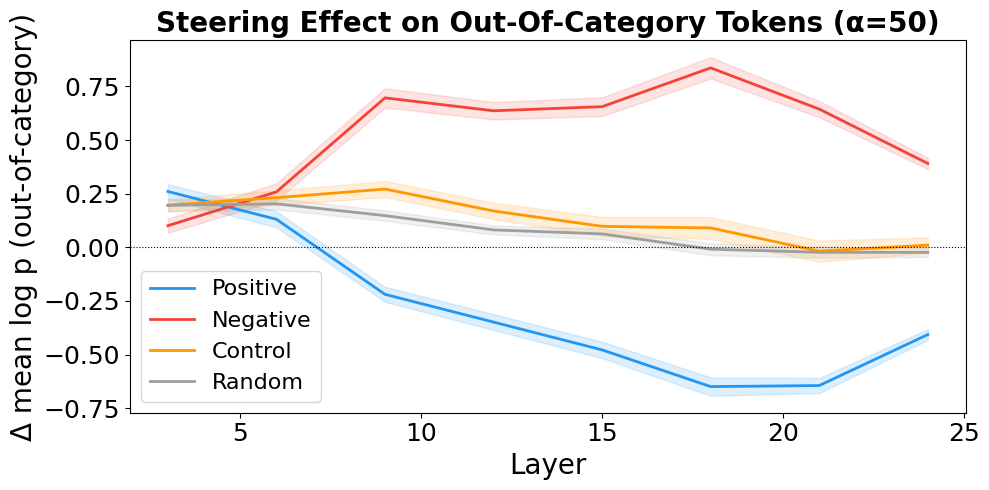

In [48]:
fig = plot_delta_by_layer(
    steered_default, "delta_out",
    ylabel="Δ mean log p (out-of-category)",
    title_suffix=f"Steering Effect on Out-Of-Category Tokens (α={DEFAULT_ALPHA})",
    model_label=MODEL_LABEL,
)
fig.savefig(os.path.join(SAVE_DIR, "steering_OUT.pdf"), bbox_inches="tight", format="pdf")

## 3. Δ Discrimination (in − out) by Layer and Condition

Positive values mean steering increased the model's tendency to prefer in-category tokens
over out-of-category tokens (i.e., concept-consistent behavior).

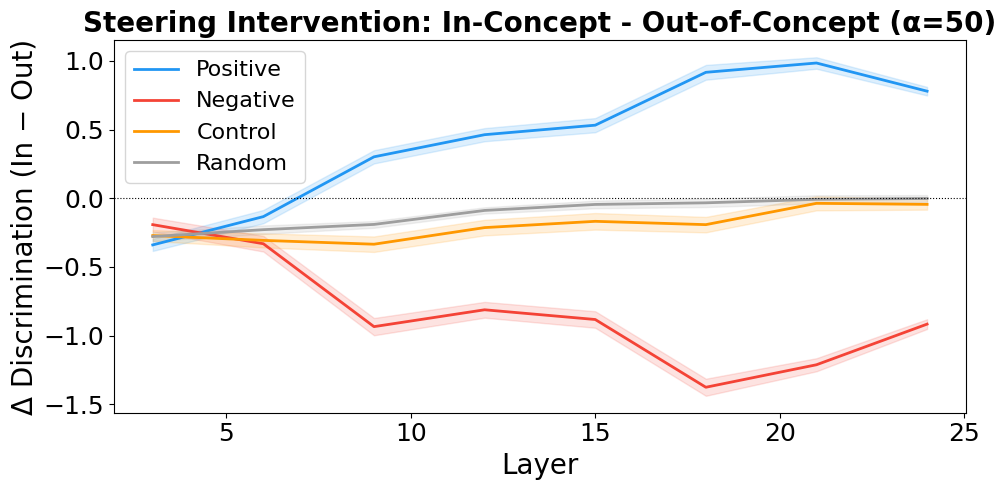

In [49]:
fig = plot_delta_by_layer(
    steered_default, "delta_discrimination",
    ylabel="Δ Discrimination (In − Out)",
    title_suffix=f"Steering Intervention: In-Concept - Out-of-Concept (α={DEFAULT_ALPHA})",
    model_label=MODEL_LABEL,
)
fig.savefig(os.path.join(SAVE_DIR, "steering.pdf"), bbox_inches="tight", format="pdf")

## 4. Alpha Scaling

How does the steering effect vary with magnitude α?

- **Left**: Δ discrimination vs layer for the `match` condition, one line per α.
- **Right**: Δ discrimination vs α at the peak layer, for all conditions.

If the trajectory direction is causally relevant, `match` should scale up with α
while `random` should remain flat.

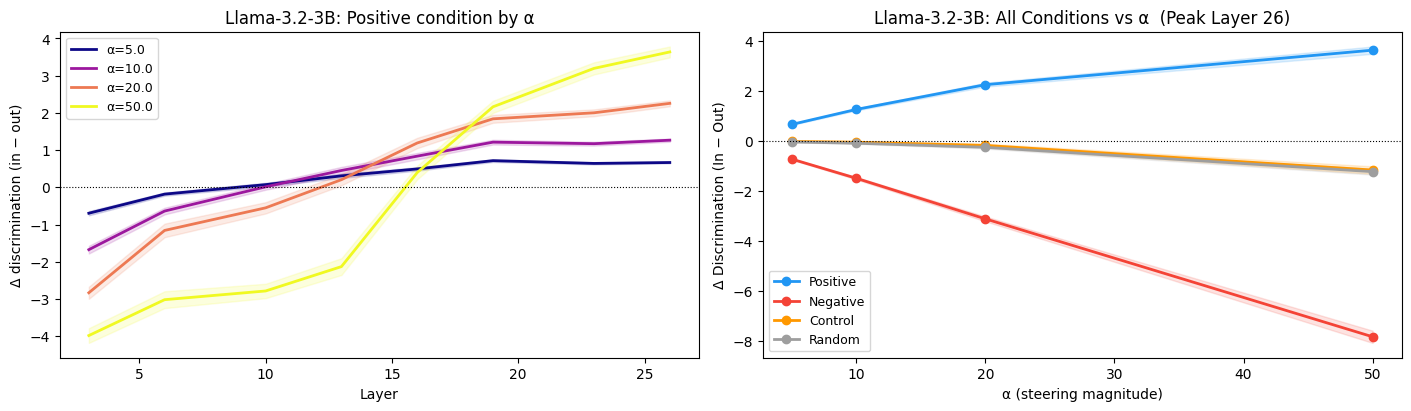

In [36]:
alpha_cmap = plt.get_cmap("plasma")
alpha_colors = {a: alpha_cmap(i / max(len(ALPHAS) - 1, 1)) for i, a in enumerate(ALPHAS)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

# Left: Positive Δ discrimination vs layer, one line per alpha
ax = axes[0]
for alpha in ALPHAS:
    sub = steered[(steered["condition"] == "Positive") & (steered["alpha"] == alpha)]
    agg = sub.groupby(["category", "layer"])["delta_discrimination"].mean().reset_index()
    stats = agg.groupby("layer")["delta_discrimination"].agg(["mean", "sem"]).reset_index()
    ax.plot(stats["layer"], stats["mean"], color=alpha_colors[alpha], linewidth=2, label=f"α={alpha}")
    ax.fill_between(stats["layer"],
                    stats["mean"] - stats["sem"],
                    stats["mean"] + stats["sem"],
                    color=alpha_colors[alpha], alpha=0.15)
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("Layer")
ax.set_ylabel("Δ discrimination (in − out)")
ax.set_title(f"{MODEL_LABEL}: Positive condition by α")
ax.legend(fontsize=9)

# Right: all conditions Δ discrimination vs alpha at peak layer
# Recompute peak layer using full steered data (default alpha)
match_agg = (
    steered_default[steered_default["condition"] == "Positive"]
    .groupby(["category", "layer"])["delta_discrimination"]
    .mean().reset_index()
    .groupby("layer")["delta_discrimination"].mean()
)
peak_layer = int(match_agg.idxmax())

ax = axes[1]
for cond in CONDITIONS:
    sub_peak = steered[(steered["condition"] == cond) & (steered["layer"] == peak_layer)]
    agg_peak = sub_peak.groupby(["category", "alpha"])["delta_discrimination"].mean().reset_index()
    stats = agg_peak.groupby("alpha")["delta_discrimination"].agg(["mean", "sem"]).reset_index()
    ax.plot(stats["alpha"], stats["mean"], color=CONDITION_COLORS[cond], linewidth=2,
            marker="o", label=cond)
    ax.fill_between(stats["alpha"],
                    stats["mean"] - stats["sem"],
                    stats["mean"] + stats["sem"],
                    color=CONDITION_COLORS[cond], alpha=0.15)
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("α (steering magnitude)")
ax.set_ylabel("Δ Discrimination (In − Out)")
ax.set_title(f"{MODEL_LABEL}: All Conditions vs α  (Peak Layer {peak_layer})")
ax.legend(fontsize=9)

plt.show()

fig.savefig(os.path.join(SAVE_DIR, "alpha_analysis.pdf"), bbox_inches="tight", format="pdf")